# Grid search

O `GridSearchCV` do Scikit-Learn é uma ferramenta utilizada para otimizar hiperparâmetros de modelos de machine learning. Hiperparâmetros são parâmetros do modelo que não são aprendidos diretamente pelos algoritmos de aprendizado, mas que precisam ser definidos antes do processo de treino. Exemplos comuns incluem a profundidade máxima de uma árvore de decisão ou a taxa de aprendizado de um modelo de gradient boosting. Encontrar os valores corretos desses hiperparâmetros pode impactar significativamente a performance do modelo.

O `GridSearchCV` automatiza esse processo, testando exaustivamente todas as combinações possíveis de valores fornecidos para os hiperparâmetros, criando uma grade (ou "grid") de opções. Ele faz isso utilizando validação cruzada (cross-validation), o que significa que o conjunto de dados é dividido em múltiplas partes (folds) e o desempenho do modelo é avaliado em diferentes subdivisões. Dessa forma, o processo minimiza o risco de overfitting e garante que o modelo generalize melhor para dados não vistos.

Após testar todas as combinações, o `GridSearchCV` retorna o conjunto de hiperparâmetros que apresentou o melhor desempenho com base na métrica de avaliação definida, como acurácia, F1-score, entre outros.

Em resumo, o `GridSearchCV` é uma abordagem sistemática e eficiente para encontrar os melhores hiperparâmetros de um modelo, evitando o trabalho manual de testar diferentes combinações e proporcionando resultados mais robustos.

https://scikit-learn.org/stable/modules/grid_search.html#grid-search

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

In [37]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    PowerTransformer,
    StandardScaler,
    QuantileTransformer,
)

PASTA_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PASTA_PROJETO) not in sys.path:
    sys.path.append(str(PASTA_PROJETO))

from src.config import DADOS_DIABETES_CATEGORIZADOS
from src.graficos import plot_comparar_metricas_modelos
from src.modelos import (
    RANDOM_STATE,
    grid_search_cv_regressor,
    organiza_resultados,
    treinar_e_validar_modelo_regressao,
)

sns.set_theme(palette="bright")

In [38]:
df = pd.read_parquet(DADOS_DIABETES_CATEGORIZADOS)

df.head()

,idade,sexo,imc,pressao_media,colesterol_total,ldl,hdl,triglicerides,glicose,target,colesterol_hdl_cat
0,59,2,32.099998,101.0,157,93.199997,38.0,4.8598,87,151,4-5
1,48,1,21.600000,87.0,183,103.199997,70.0,3.8918,69,75,2-3
2,72,2,30.500000,93.0,156,93.599998,41.0,4.6728,85,141,4-5
3,24,1,25.299999,84.0,198,131.399994,40.0,4.8903,89,206,4-5
4,50,1,23.000000,101.0,192,125.400002,52.0,4.2905,80,135,4-5


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   idade               442 non-null    int8    
 1   sexo                442 non-null    int8    
 2   imc                 442 non-null    float32 
 3   pressao_media       442 non-null    float32 
 4   colesterol_total    442 non-null    int16   
 5   ldl                 442 non-null    float32 
 6   hdl                 442 non-null    float32 
 7   triglicerides       442 non-null    float32 
 8   glicose             442 non-null    int8    
 9   target              442 non-null    int16   
 10  colesterol_hdl_cat  442 non-null    category
dtypes: category(1), float32(5), int16(2), int8(3)
memory usage: 12.3 KB


In [40]:
X = df.drop(columns="target")
y = df["target"]

In [41]:
colunas_power_transform = ["imc", "ldl", "hdl", "colesterol_total"]

coluna_target = ["target"]

coluna_ordinal_encoder = ["colesterol_hdl_cat"]

coluna_one_hot_encoder = ["sexo"]

colunas_standard_scaler = [
    coluna
    for coluna in df.columns
    if coluna not in colunas_power_transform + coluna_target + coluna_ordinal_encoder + coluna_one_hot_encoder
]

colunas_standard_scaler

['idade', 'pressao_media', 'triglicerides', 'glicose']

In [42]:
categorias_ordinal_encoder = [
    ["2-3", "4-5", "6+"],
]

In [43]:
preprocessamento_categoricas = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ],
    remainder="passthrough",
)

preprocessamento_simples = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
        ("standard_scaler", StandardScaler(), X.columns.difference(coluna_ordinal_encoder + coluna_one_hot_encoder)),
    ],
    remainder="passthrough",
)

preprocessamento_completo = ColumnTransformer(
    [
        ("power_transform", PowerTransformer(method="box-cox"), colunas_power_transform),
        ("standard_scaler", StandardScaler(), colunas_standard_scaler),
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ]
)

target_transformer = QuantileTransformer(n_quantiles=20, output_distribution="normal")

In [44]:
ridge_regressor = Ridge()

In [45]:
param_grid = {
    "regressor__reg__alpha": [1E-2, 5E-2, 0.1, 1.0, 5.0, 10], 
    "regressor__preprocessor": [preprocessamento_categoricas, preprocessamento_simples, preprocessamento_completo],
    "transformer": [target_transformer, None]
}

In [46]:
grid_search = grid_search_cv_regressor(
    regressor=ridge_regressor,
    param_grid=param_grid,
    preprocessor=preprocessamento_categoricas,
    target_transformer=target_transformer,
)

grid_search

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(remainder='passthrough',
                                                                                               transformers=[('ordinal_encoder',
                                                                                                              OrdinalEncoder(categories=[['2-3',
                                                                                                                                          '4-5',
                                                                                                                                          '6+']]),
                                                                                                              ['colesterol_hdl_cat']),
                                                                                                             ('one_hot_encoder',
                                                                                                              OneHotEncoder(drop='if_binary'),
                                                                                                              ['sexo'])]...
                                                                                                                  '6+']]),
                                                                                      ['colesterol_hdl_cat']),
                                                                                     ('one_hot_encoder',
                                                                                      OneHotEncoder(drop='if_binary'),
                                                                                      ['sexo'])])],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal'),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [47]:
grid_search.fit(X, y)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(remainder='passthrough',
                                                                                               transformers=[('ordinal_encoder',
                                                                                                              OrdinalEncoder(categories=[['2-3',
                                                                                                                                          '4-5',
                                                                                                                                          '6+']]),
                                                                                                              ['colesterol_hdl_cat']),
                                                                                                             ('one_hot_encoder',
                                                                                                              OneHotEncoder(drop='if_binary'),
                                                                                                              ['sexo'])]...
                                                                                                                  '6+']]),
                                                                                      ['colesterol_hdl_cat']),
                                                                                     ('one_hot_encoder',
                                                                                      OneHotEncoder(drop='if_binary'),
                                                                                      ['sexo'])])],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal'),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [48]:
grid_search.best_params_

{'regressor__preprocessor': ColumnTransformer(remainder='passthrough',
                   transformers=[('ordinal_encoder',
                                  OrdinalEncoder(categories=[['2-3', '4-5',
                                                              '6+']]),
                                  ['colesterol_hdl_cat']),
                                 ('one_hot_encoder',
                                  OneHotEncoder(drop='if_binary'), ['sexo']),
                                 ('standard_scaler', StandardScaler(),
                                  Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
        'pressao_media', 'triglicerides'],
       dtype='object'))]),
 'regressor__reg__alpha': 0.1,
 'transformer': None}

In [49]:
grid_search.best_score_

-54.64487672890368

In [50]:
grid_search.best_estimator_

TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(remainder='passthrough',
                                                                        transformers=[('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo']),
                                                                                      ('standard_scaler',
                                                                                       StandardScaler(),
                                                                                       Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])),
                                                     ('reg',
                                                      Ridge(alpha=0.1))]))

In [51]:
print(*grid_search.cv_results_.keys(), sep="\n")

mean_fit_time
std_fit_time
mean_score_time
std_score_time
param_regressor__preprocessor
param_regressor__reg__alpha
param_transformer
params
split0_test_r2
split1_test_r2
split2_test_r2
split3_test_r2
split4_test_r2
mean_test_r2
std_test_r2
rank_test_r2
split0_test_neg_mean_absolute_error
split1_test_neg_mean_absolute_error
split2_test_neg_mean_absolute_error
split3_test_neg_mean_absolute_error
split4_test_neg_mean_absolute_error
mean_test_neg_mean_absolute_error
std_test_neg_mean_absolute_error
rank_test_neg_mean_absolute_error
split0_test_neg_root_mean_squared_error
split1_test_neg_root_mean_squared_error
split2_test_neg_root_mean_squared_error
split3_test_neg_root_mean_squared_error
split4_test_neg_root_mean_squared_error
mean_test_neg_root_mean_squared_error
std_test_neg_root_mean_squared_error
rank_test_neg_root_mean_squared_error


In [52]:
grid_search.cv_results_["split0_test_r2"]

array([0.45675664, 0.45229575, 0.45668958, 0.45227946, 0.45660568,
       0.45225839, 0.45506987, 0.45177188, 0.44799051, 0.44881751,
       0.44078878, 0.44556707, 0.45677561, 0.45231426, 0.45678383,
       0.45237116, 0.45679307, 0.4524398 , 0.45696273, 0.4533428 ,
       0.45691518, 0.45501614, 0.45758828, 0.45614825, 0.45109676,
       0.44182063, 0.45104308, 0.44179854, 0.45097703, 0.44177112,
       0.44992047, 0.44133091, 0.44751062, 0.44053978, 0.44717549,
       0.44074843])

In [53]:
grid_search.cv_results_["mean_test_r2"]

array([0.47574658, 0.48245776, 0.47571512, 0.48246349, 0.47567559,
       0.4824695 , 0.47482587, 0.48239831, 0.47046456, 0.48029887,
       0.46556903, 0.47718963, 0.47574502, 0.48245927, 0.47570589,
       0.48247076, 0.47565492, 0.4824835 , 0.47474888, 0.48252263,
       0.47240254, 0.48201188, 0.47172563, 0.48158809, 0.47668682,
       0.47602721, 0.47666525, 0.47604542, 0.47663741, 0.47606647,
       0.47599667, 0.47622784, 0.47378012, 0.47578505, 0.47274427,
       0.47519394])

In [54]:
max(grid_search.cv_results_["mean_test_r2"])

0.4825226261071613

In [55]:
min(grid_search.cv_results_["mean_test_r2"])

0.4655690322819295

In [56]:
max(grid_search.cv_results_["mean_test_neg_root_mean_squared_error"])

-54.64487672890368

In [57]:
len(grid_search.cv_results_["split0_test_r2"])

36

In [58]:
len(grid_search.cv_results_["split0_test_r2"])

36

In [59]:
grid_search.best_estimator_

TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(remainder='passthrough',
                                                                        transformers=[('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo']),
                                                                                      ('standard_scaler',
                                                                                       StandardScaler(),
                                                                                       Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])),
                                                     ('reg',
                                                      Ridge(alpha=0.1))]))

In [60]:
grid_search.best_estimator_.regressor_["preprocessor"]

ColumnTransformer(remainder='passthrough',
                  transformers=[('ordinal_encoder',
                                 OrdinalEncoder(categories=[['2-3', '4-5',
                                                             '6+']]),
                                 ['colesterol_hdl_cat']),
                                ('one_hot_encoder',
                                 OneHotEncoder(drop='if_binary'), ['sexo']),
                                ('standard_scaler', StandardScaler(),
                                 Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])

In [61]:
grid_search.best_estimator_.regressor_["preprocessor"]

ColumnTransformer(remainder='passthrough',
                  transformers=[('ordinal_encoder',
                                 OrdinalEncoder(categories=[['2-3', '4-5',
                                                             '6+']]),
                                 ['colesterol_hdl_cat']),
                                ('one_hot_encoder',
                                 OneHotEncoder(drop='if_binary'), ['sexo']),
                                ('standard_scaler', StandardScaler(),
                                 Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])

In [62]:
grid_search.best_estimator_.regressor_["reg"]

Ridge(alpha=0.1)

In [63]:
regressors = {
    "DummyRegressor": {
        "preprocessor": None,
        "regressor": DummyRegressor(strategy="mean"),
        "target_transformer": None,
    },
    "LinearRegression_pre_simples": {
        "preprocessor": preprocessamento_simples,
        "regressor": LinearRegression(),
        "target_transformer": None,
    },
    "Ridge_grid_search": {
        "preprocessor": grid_search.best_estimator_.regressor_["preprocessor"],
        "regressor": grid_search.best_estimator_.regressor["reg"],
        "target_transformer": None,
    },
    
}

In [64]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_regressao(X, y, **regressor)
    for nome_modelo, regressor in regressors.items()
}

resultados

{'DummyRegressor': {'fit_time': array([0.00647998, 0.00331998, 0.00383639, 0.00223255, 0.00154877]),
  'score_time': array([0.00391603, 0.00405359, 0.00371957, 0.0021379 , 0.00197458]),
  'test_r2': array([-0.01196298, -0.02697753, -0.01530397, -0.00021233, -0.04231598]),
  'test_neg_mean_absolute_error': array([-64.00646147, -70.57793551, -59.82954545, -70.05392912,
         -65.42565485]),
  'test_neg_root_mean_squared_error': array([-73.22249284, -80.04318688, -74.33859714, -82.04745226,
         -76.3152967 ])},
 'LinearRegression_pre_simples': {'fit_time': array([0.02730775, 0.01078391, 0.01385069, 0.01085329, 0.01063132]),
  'score_time': array([0.00795412, 0.00730824, 0.00764179, 0.00720716, 0.01054382]),
  'test_r2': array([0.45229974, 0.57370343, 0.40683321, 0.58812556, 0.39131907]),
  'test_neg_mean_absolute_error': array([-42.98079751, -41.53071355, -46.70245302, -41.89567184,
         -47.42385601]),
  'test_neg_root_mean_squared_error': array([-53.86834947, -51.57031955, -

In [65]:
df_resultados = organiza_resultados(resultados)

df_resultados

,model,fit_time,score_time,test_r2,test_neg_mean_absolute_error,test_neg_root_mean_squared_error,time_seconds
0,DummyRegressor,0.006480,0.003916,-0.011963,-64.006461,-73.222493,0.010396
1,DummyRegressor,0.003320,0.004054,-0.026978,-70.577936,-80.043187,0.007374
2,DummyRegressor,0.003836,0.003720,-0.015304,-59.829545,-74.338597,0.007556
3,DummyRegressor,0.002233,0.002138,-0.000212,-70.053929,-82.047452,0.004370
4,DummyRegressor,0.001549,0.001975,-0.042316,-65.425655,-76.315297,0.003523
5,LinearRegression_pre_simples,0.027308,0.007954,0.452300,-42.980798,-53.868349,0.035262
6,LinearRegression_pre_simples,0.010784,0.007308,0.573703,-41.530714,-51.570320,0.018092
7,LinearRegression_pre_simples,0.013851,0.007642,0.406833,-46.702453,-56.820458,0.021492
8,LinearRegression_pre_simples,0.010853,0.007207,0.588126,-41.895672,-52.650369,0.018060
9,LinearRegression_pre_simples,0.010631,0.010544,0.391319,-47.423856,-58.318554,0.021175


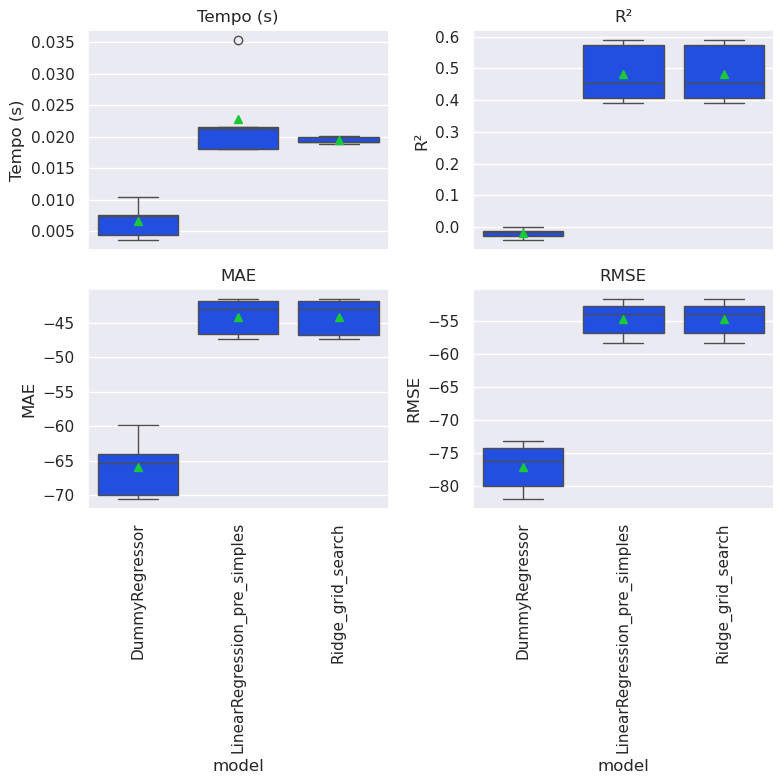

In [66]:
plot_comparar_metricas_modelos(df_resultados)